##Data is from this repo https://github.com/IBM/telco-customer-churn-on-icp4d/tree/master/data

In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score



In [2]:
#Load dataset
df = pd.read_csv('data/churn.csv')

df.info()
 

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df["Churn"].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [5]:
df["Churn"].value_counts(normalize=True)

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [6]:
#Target variable - replace Yes and No with 1 and 0
df['Churn'] = df["Churn"].replace({
    "Yes": 1,
    "No": 0
})
df["Churn"].unique()

array([0, 1], dtype=object)

In [7]:
#convert total charges to numeric from string
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors='coerce')

#check for missing values in total charges
print(f"Missing values: {df['TotalCharges'].isnull().sum()}")

Missing values: 11


In [8]:
df = df.dropna()

In [ ]:
# Select continuous numeric variables
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Compute the correlation matrix
corr_matrix = df[numeric_cols].corr()

# Plot the heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix of Continuous Features')
plt.show()

Churn rate by gender gender
Female    26.959518
Male      26.204565
Name: Churn, dtype: object


C:\Users\User\AppData\Local\Temp\ipykernel_30272\2534820779.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df['gender'], y=df['Churn'], errorbar=None, palette='pastel')


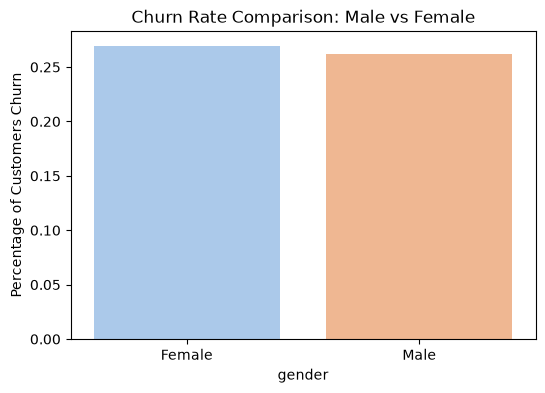

In [10]:
#calculate percentage of churn for each gender
gender_churn = df.groupby("gender")['Churn'].mean()*100
print(f"Churn rate by gender {gender_churn}")

#visual representation
plt.figure(figsize=(6,4))
sns.barplot(x=df['gender'], y=df['Churn'], errorbar=None, palette='pastel')
plt.title('Churn Rate Comparison: Male vs Female')
plt.ylabel('Percentage of Customers Churn')
plt.show()


In [11]:
# Create a cross-tabulation of InternetService vs OnlineSecurity
cross_tab = pd.crosstab(df['InternetService'], df['OnlineSecurity'])
print("Cross-tabulation of Internet Service Type vs Online Security:")
print(cross_tab)

# Let's count how many times 'No internet service' appears across these columns
addon_columns = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
print("\nVerifying 'No internet service' across all add-ons:")
for col in addon_columns:
    no_internet_count = (df[col] == 'No internet service').sum()
    print(f"Column '{col}' has {no_internet_count} rows tagged as 'No internet service'")

Cross-tabulation of Internet Service Type vs Online Security:
OnlineSecurity     No  No internet service   Yes
InternetService                                 
DSL              1240                    0  1176
Fiber optic      2257                    0   839
No                  0                 1520     0

Verifying 'No internet service' across all add-ons:
Column 'OnlineSecurity' has 1520 rows tagged as 'No internet service'
Column 'OnlineBackup' has 1520 rows tagged as 'No internet service'
Column 'DeviceProtection' has 1520 rows tagged as 'No internet service'
Column 'TechSupport' has 1520 rows tagged as 'No internet service'
Column 'StreamingTV' has 1520 rows tagged as 'No internet service'
Column 'StreamingMovies' has 1520 rows tagged as 'No internet service'


In [12]:
#Drop customerId since no predictive power
df = df.drop(columns='customerID')

In [13]:
df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_1
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,True,False,True,False,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,True,False,False,False,False,True,False
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,True,False,False,True,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,True,False,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,True,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,True,True,True,True,False,True,...,True,False,True,True,False,True,False,False,True,False
7039,0,72,103.20,7362.90,False,True,True,True,False,True,...,True,False,True,True,False,True,True,False,False,False
7040,0,11,29.60,346.45,False,True,True,False,True,False,...,False,False,False,False,False,True,False,True,False,False
7041,1,4,74.40,306.60,True,True,False,True,False,True,...,False,False,False,False,False,True,False,False,True,True


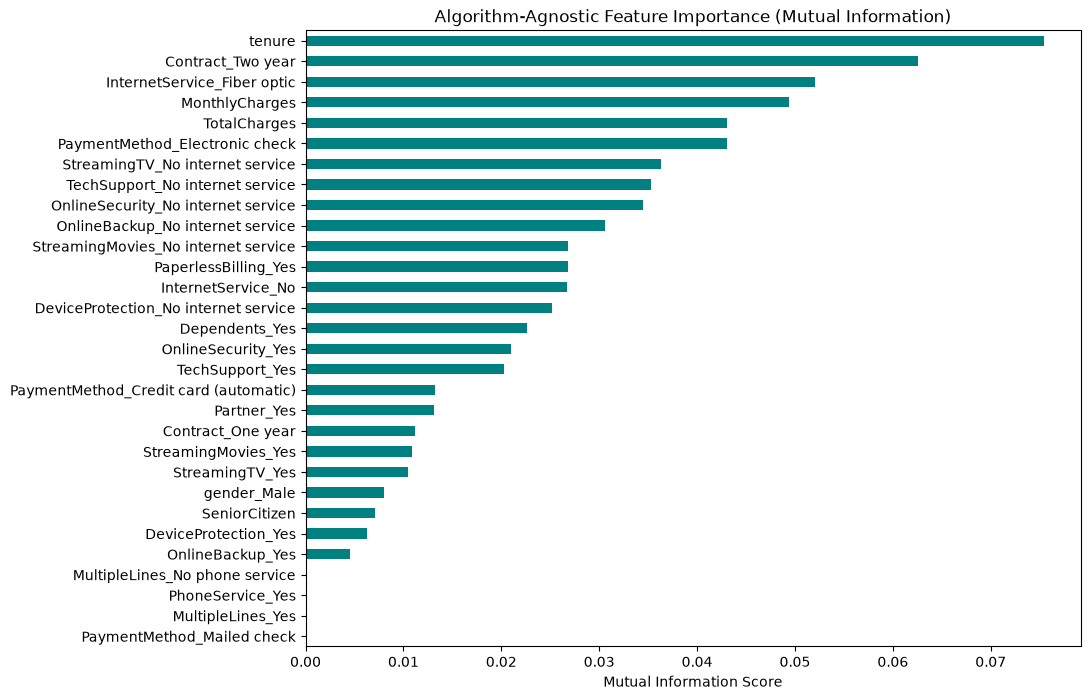

Top 5 and Bottom 5 features by pure statistical dependency:
tenure                         0.075402
Contract_Two year              0.062579
InternetService_Fiber optic    0.052035
MonthlyCharges                 0.049388
TotalCharges                   0.043091
Name: Mutual Information, dtype: float64 
 OnlineBackup_Yes                  0.004554
MultipleLines_No phone service    0.000000
PhoneService_Yes                  0.000000
MultipleLines_Yes                 0.000000
PaymentMethod_Mailed check        0.000000
Name: Mutual Information, dtype: float64


In [15]:
# 1. We must use our encoded dataset to get numeric vectors for calculation
X_encoded = df_encoded.drop(columns=['Churn_1'])
y_encoded = df_encoded['Churn_1']

# 2. Calculate Mutual Information scores
mi_scores = mutual_info_classif(X_encoded, y_encoded, random_state=42)
mi_scores = pd.Series(mi_scores, name="Mutual Information", index=X_encoded.columns)
mi_scores = mi_scores.sort_values(ascending=False)

# 3. Plot the raw statistical dependencies
plt.figure(figsize=(10, 8))
mi_scores.plot(kind='barh', color='teal')
plt.title('Algorithm-Agnostic Feature Importance (Mutual Information)')
plt.xlabel('Mutual Information Score')
plt.gca().invert_yaxis()
plt.show()

print("Top 5 and Bottom 5 features by pure statistical dependency:")
print(mi_scores.head(5), "\n", mi_scores.tail(5))


In [18]:
# Separate our features (X) from our target label (y)
X = df_encoded.drop(columns=['Churn_1'])
y = df_encoded['Churn_1']

# Split into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (5625, 30)
Testing features shape: (1407, 30)


In [19]:
# 1. Initialize the scaler
scaler = StandardScaler()

# 2. Fit and transform the training data, then transform the test data
# (Notice we only 'fit' on the training data to prevent data leakage!)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Initialize a baseline KNN model with an arbitrary K=5
knn = KNeighborsClassifier(n_neighbors=5)

# 4. Train the model
knn.fit(X_train_scaled, y_train)

# 5. Make predictions on our test set
y_pred = knn.predict(X_test_scaled)

# 6. Evaluate the baseline performance
print(f"Baseline Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Baseline Accuracy: 0.7534

Classification Report:
              precision    recall  f1-score   support

       False       0.83      0.83      0.83      1033
        True       0.54      0.53      0.54       374

    accuracy                           0.75      1407
   macro avg       0.68      0.68      0.68      1407
weighted avg       0.75      0.75      0.75      1407



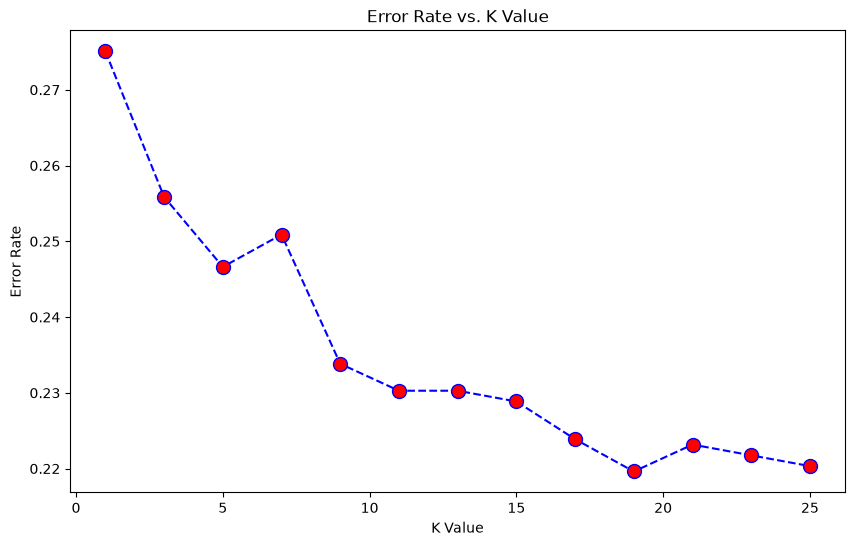

In [20]:
error_rate = []

# Check odd values of K
for i in range(1, 26, 2):
    knn_test = KNeighborsClassifier(n_neighbors=i)
    knn_test.fit(X_train_scaled, y_train)
    pred_i = knn_test.predict(X_test_scaled)
    # Calculate the average error rate
    error_rate.append(np.mean(pred_i != y_test))

# Plot the error rates
plt.figure(figsize=(10, 6))
plt.plot(range(1, 26, 2), error_rate, color='blue', linestyle='dashed', marker='o', markerfacecolor='red', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K Value')
plt.ylabel('Error Rate')
plt.show()

In [21]:
# 1. Initialize the optimized model with your chosen K
final_knn = KNeighborsClassifier(n_neighbors=19)

# 2. Fit the model on our scaled training features
final_knn.fit(X_train_scaled, y_train)

# 3. Predict the test values
y_pred_final = final_knn.predict(X_test_scaled)

# 4. Show the final scoring metrics
print(f"Optimized Accuracy (K=19): {accuracy_score(y_test, y_pred_final):.4f}\n")
print("Optimized Classification Report:")
print(classification_report(y_test, y_pred_final))

Optimized Accuracy (K=19): 0.7804

Optimized Classification Report:
              precision    recall  f1-score   support

       False       0.85      0.86      0.85      1033
        True       0.59      0.57      0.58       374

    accuracy                           0.78      1407
   macro avg       0.72      0.71      0.71      1407
weighted avg       0.78      0.78      0.78      1407

